In [9]:
import pymc as pm
import pytensor.tensor as at
import numpy as np
import arviz as az
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from pytensor.tensor.random.utils import params_broadcast_shapes

In [14]:
# ---------- constants ----------
# latent sample size
n         = 100           
Xo_obs    = 1.37
Predo_obs = 2.11
tiny      = 1e-3

# --------------------------------

with pm.Model() as m:
    # hyper‑priors
    αXμ  = pm.Normal('αXμ',  10, 5)
    αXσ  = pm.Exponential('αXσ', 1)
    αAμ  = pm.Normal('αAμ',  5, 1)
    αYσ  = pm.Exponential('αYσ', 1)
    NE   = pm.Normal('NE',  -0.1, 1)

    # deterministic helpers
    a  = pm.Deterministic('a', 1 + NE)
    b  = pm.Deterministic('b', NE * αAμ)
    sy2 = pm.Deterministic('sy2', NE**2 + αYσ**2)

    # ── draw the three low‑dimensional auxiliaries ───────────────
    T1 = pm.Normal('T1',  0, 1,  shape=())   # will be scaled by sqrt(n)
    T2 = pm.ChiSquared('T2', n)
    T3 = pm.Normal('T3',  0, 1,  shape=())

    # scale them (see derivation)
    T1s = at.sqrt(n) * T1
    T3s = at.sqrt(n) * T3

    sx2 = αXσ**2
    deltax = αXμ / αXσ

    Sxx = pm.Deterministic('Sxx', sx2 * (n*deltax**2 + 2*deltax*T1s + T2))
    Sxy = pm.Deterministic(
            'Sxy',
            a*Sxx + b*n*αXμ + b*αXσ*T1s + αXσ*at.sqrt(sy2)*T3s)

    phi = pm.Deterministic('phi', Sxy / Sxx)

    # only observed data in the entire model
    pm.Normal('Predo', mu = phi * Xo_obs, sigma = tiny, observed = Predo_obs)

    trace = pm.sample(3000, target_accept=.97, chains=4, random_seed=42)

 Progress                    Draws   Divergences   Step size   Grad evals   Sampling Speed   Elapsed   Remaining  
 ───────────────────────────────────────────────────────────────────────────────────────────────────────────────── 
  ━━━━━━━━━━━━━━━━━━━━━━━━━   4000    105           0.00        511          20.76 draws/s    0:03:12   0:00:00    
  ━━━━━━━━━━━━━━━━━━━━━━━━━   4000    30            0.00        1023         18.71 draws/s    0:03:33   0:00:00    
  ━━━━━━━━━━━━━━━━━━━━━━━━━   4000    19            0.00        1023         18.29 draws/s    0:03:38   0:00:00    
  ━━━━━━━━━━━━━━━━━━━━━━━━━   4000    37            0.00        1023         18.41 draws/s    0:03:37   0:00:00

Sampling 4 chains for 1_000 tune and 3_000 draw iterations (4_000 + 12_000 draws total) took 219 seconds.
There were 191 divergences after tuning. Increase `target_accept` or reparameterize.
Chain 2 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.
Chain 3 reached the maximum tree depth. Increase `max_treedepth`, increase `target_accept` or reparameterize.


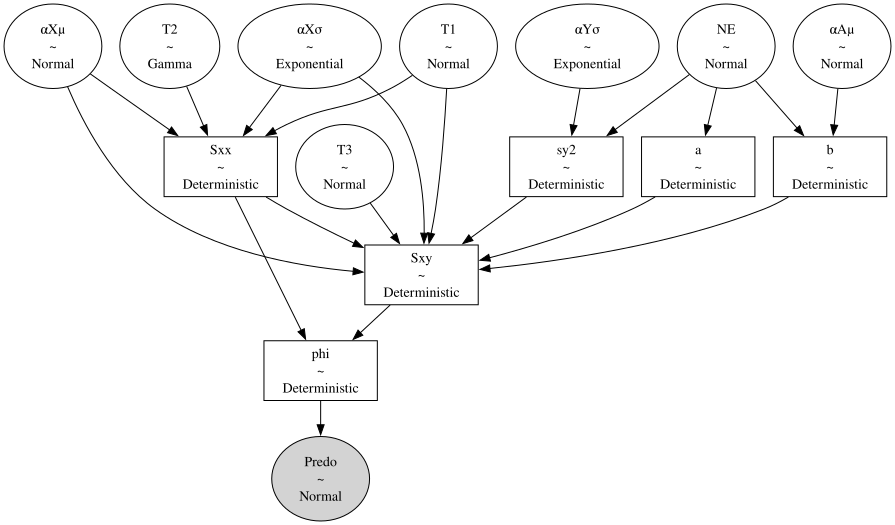

In [15]:
pm.model_to_graphviz(m)

array([[<Axes: title={'center': 'αXμ'}>, <Axes: title={'center': 'αAμ'}>,
        <Axes: title={'center': 'NE'}>, <Axes: title={'center': 'T1'}>],
       [<Axes: title={'center': 'T3'}>, <Axes: title={'center': 'αXσ'}>,
        <Axes: title={'center': 'αYσ'}>, <Axes: title={'center': 'T2'}>],
       [<Axes: title={'center': 'a'}>, <Axes: title={'center': 'b'}>,
        <Axes: title={'center': 'sy2'}>, <Axes: title={'center': 'Sxx'}>],
       [<Axes: title={'center': 'Sxy'}>, <Axes: title={'center': 'phi'}>,
        <Axes: >, <Axes: >]], dtype=object)

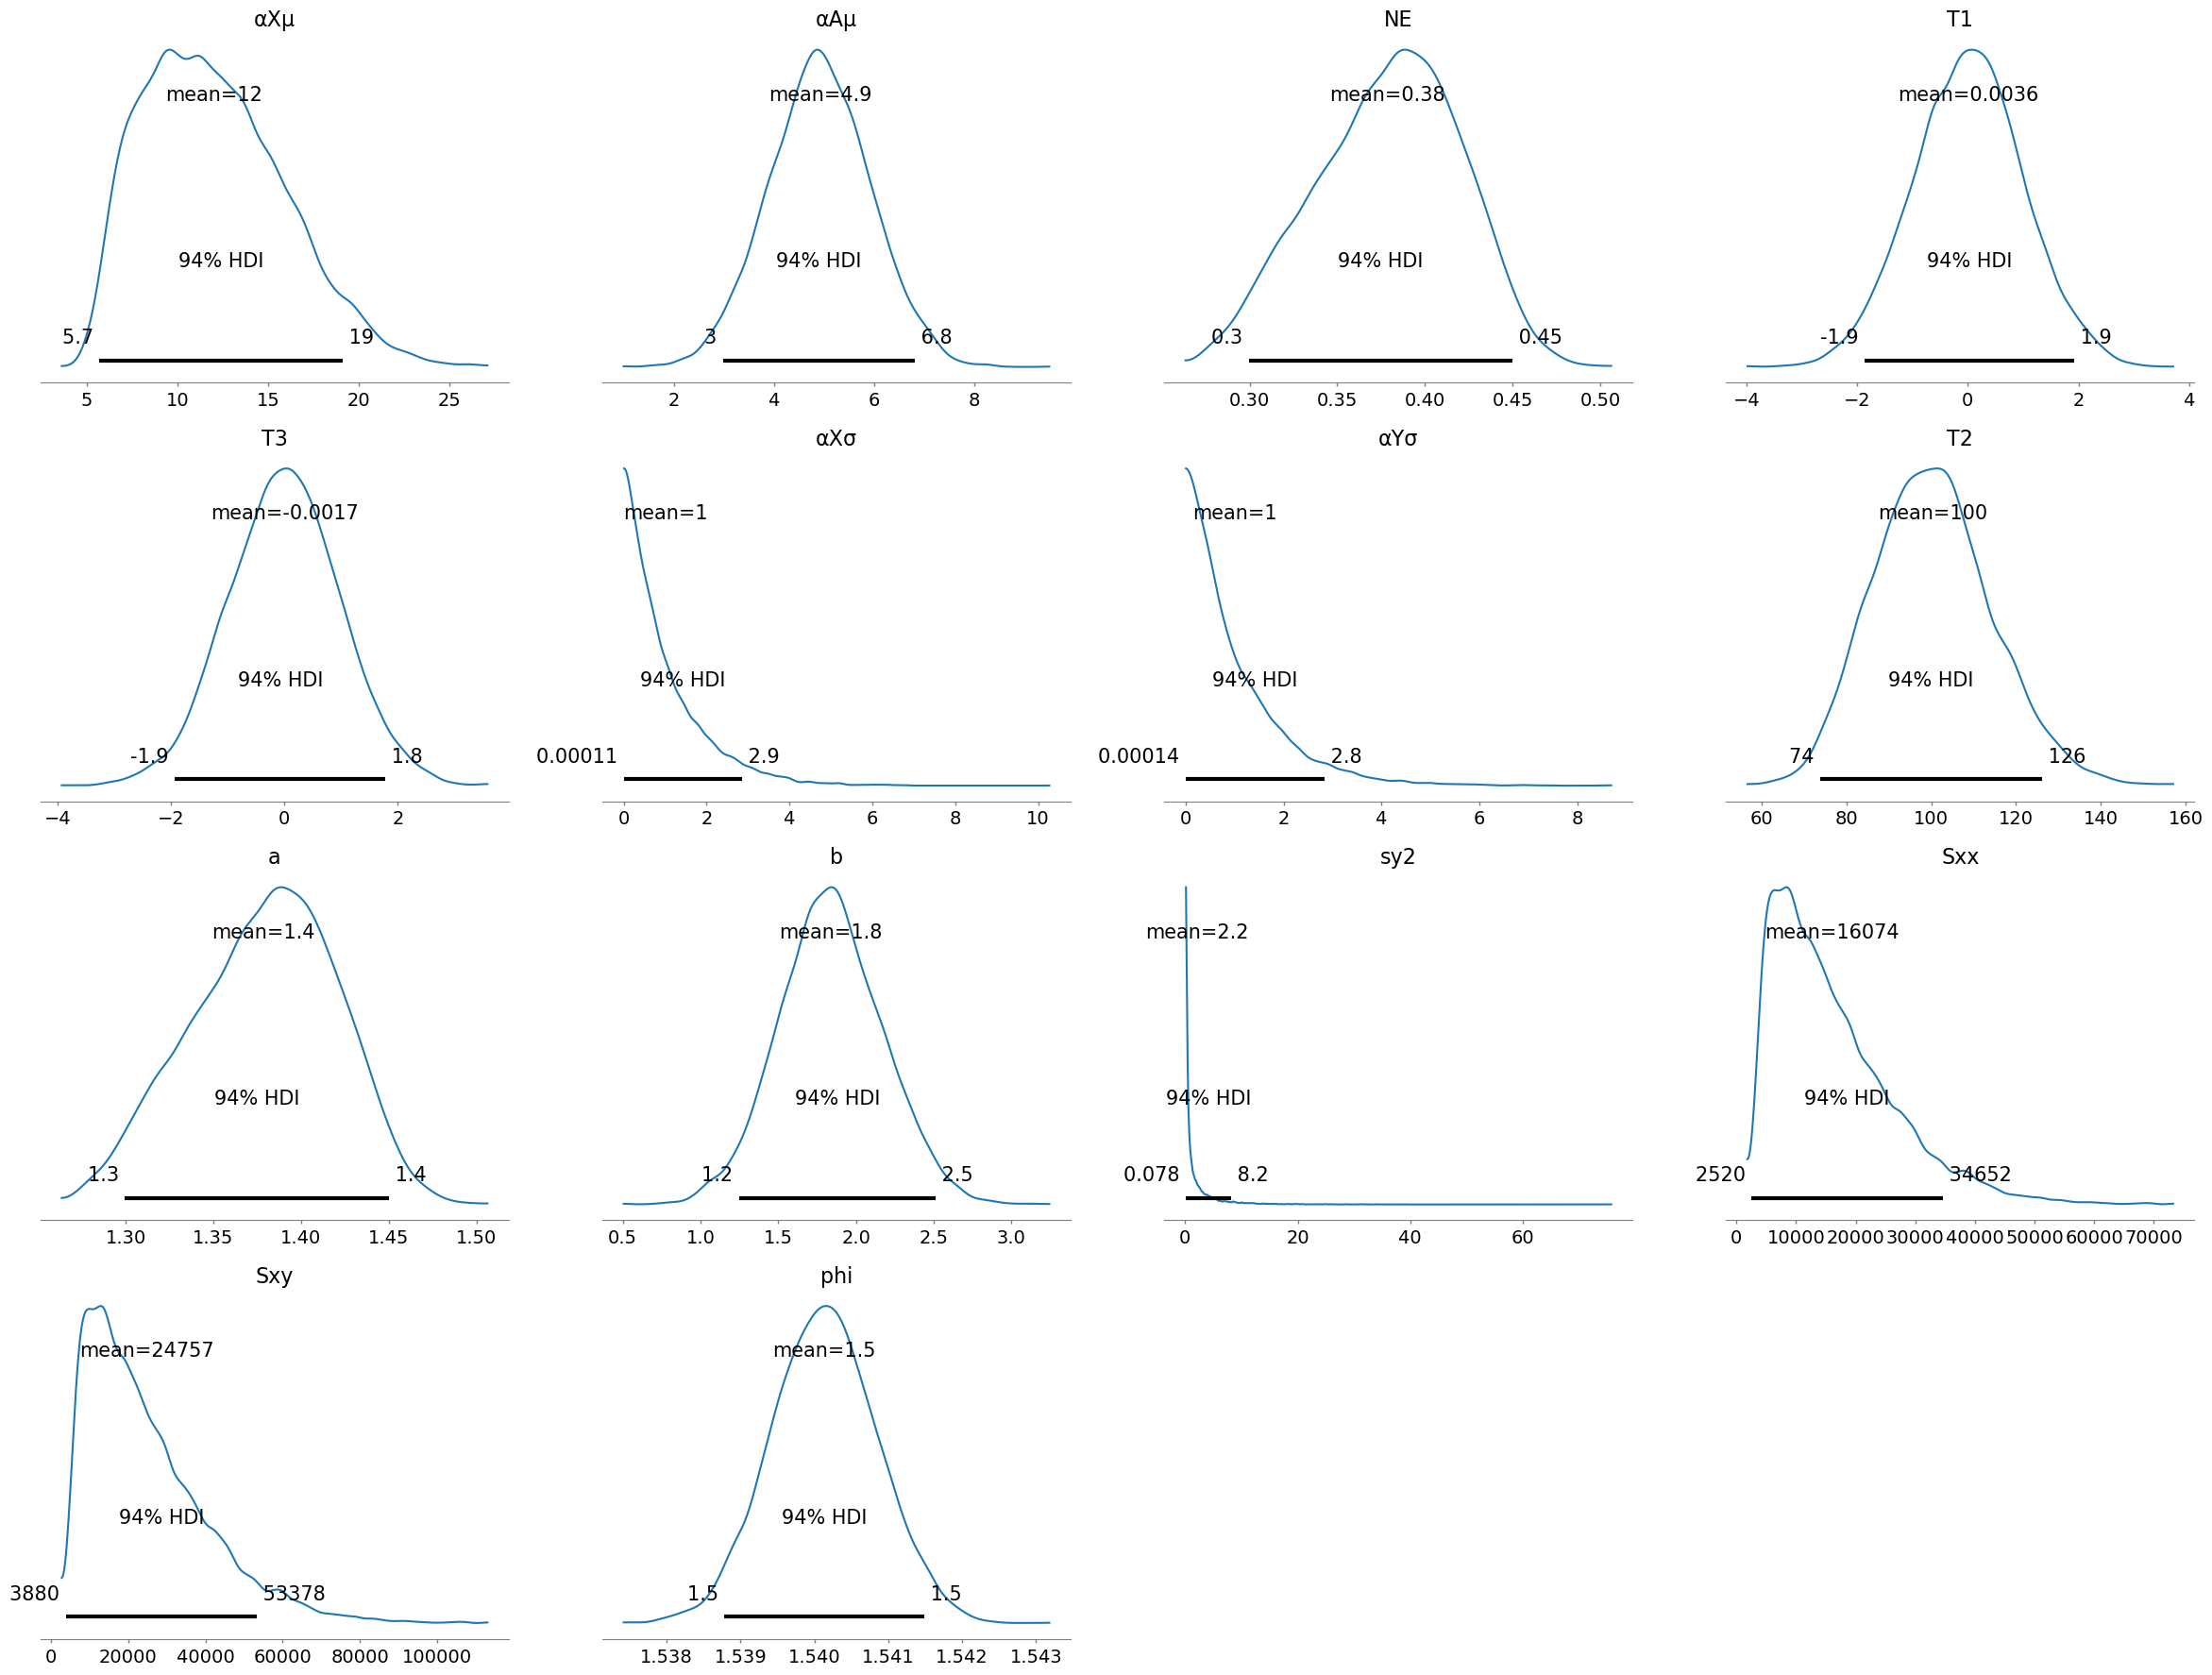

In [4]:
az.plot_posterior(
    trace, 
    # filter_vars=""
)

In [5]:
rng = np.random.default_rng(123)

# one predictive sample per posterior draw
Xnew_samples   = rng.normal(loc=trace.posterior['αXμ'],
                            scale=trace.posterior['αXσ'])

phi_samples    = trace.posterior['phi']
Prednew_samples = phi_samples * Xnew_samples

# Shape (chains, draws); flatten if you wish
pred_vec = np.asarray(Prednew_samples).ravel()

In [12]:
Prednew_samples.shape

(4, 3000)

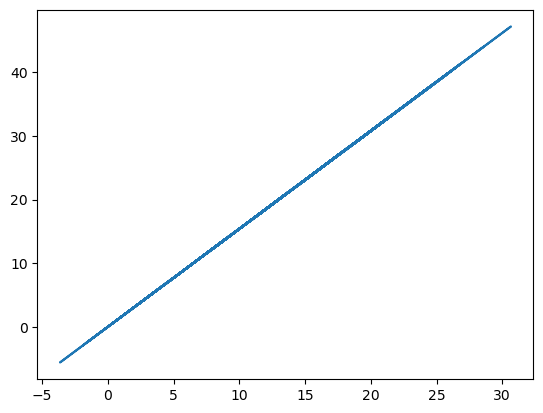

In [13]:
plt.plot(Xnew_samples.flatten(), pred_vec)